# EDA: отток абонентов Telco Customer Churn

**Команда 2 · кейс 2 · объединённая версия от 11 ноября 2026 года**

Цель — описать данные, проверить их качество и найти связи с `Churn`,
которые стоит проверить при моделировании вероятности ухода.
Единица наблюдения — абонент; одна строка не является отдельным платежом.

Этот ноутбук объединяет три авторские работы. Повторяющиеся импорты,
однотипные графики и повторные выводы сведены в общие блоки.

| Источник | Что использовано |
|---|---|
| Катрина Ефимова, [`katrina_eda`, a52bf9a](https://github.com/ozzzpo/imo-practicum/blob/a52bf9a/notebooks/01_eda_efimova.ipynb) | Разбор пропусков, интервалы срока и стоимости, совместные группировки, Pearson/Spearman, ограничения выводов |
| Алексей Щербаха, [`shcherbakha/eda`, e8a3549](https://github.com/ozzzpo/imo-practicum/blob/e8a3549/notebooks/01_eda_shcherbakha.ipynb) | Согласованность услуг, совпадающие профили, доли оттока с размерами групп, сравнение договора внутри интервалов срока |
| Вадим Семенов, [`Create_1st_meeting_plan`, 147f7c2](https://github.com/ozzzpo/imo-practicum/blob/147f7c2/notebooks/semenov_vadim_v1.ipynb) | Паспорт полей, компактные распределения и итоговая таблица «наблюдение → подготовка → гипотеза» |

Исходные версии сохранены в истории Git. Участники должны проверить
результаты и самостоятельно сформулировать ключевые выводы.

Основание: [кейс](../context/case-02.md), [план EDA](../docs/eda-plan.md),
[ожидания курса](../context/requirements.md#ожидания-от-eda),
[журнал решений](../docs/decisions.md).

## 1. Данные и воспроизводимость

Перед запуском: `uv sync`. Отсутствующий CSV версии 1 скачивается с Kaggle;
ручной способ — в [data/README.md](../data/README.md).
Выбрать Python из `.venv`, выполнить **Restart Kernel → Run All**.
Рабочей папкой может быть корень проекта или `notebooks/`.
Первая загрузка явно разрешена параметром `download=True`: скачанный CSV
сохраняется только после проверки хеша. Существующий файл читается без сети
и не перезаписывается. Установка пакетов в ячейках не выполняется.

| Группа | Поля и смысл |
|---|---|
| Идентификатор | `customerID` — ID абонента; исключается из признаков модели и корреляций |
| Демография | `gender`, `SeniorCitizen` (флаг 0/1), `Partner`, `Dependents` |
| Договор | `tenure` — месяцы обслуживания; `Contract` — срок договора; `PaperlessBilling` — электронный счёт |
| Телефония | `PhoneService`, `MultipleLines` |
| Интернет | `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Начисления и оплата | `PaymentMethod` — способ оплаты; `MonthlyCharges` — текущая месячная плата; `TotalCharges` — накопленные начисления |
| Цель | `Churn` — уход за последний месяц по описанию набора, `Yes` / `No` |

Истории тарифов и отдельных транзакций, дат первого счёта и причин ухода
в этом CSV нет. `No internet service` и `No phone service` — содержательные
категории отсутствия основной услуги.

In [1]:
from pathlib import Path
from importlib.metadata import version
from textwrap import fill
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik  # регистрирует DataFrame.phik_matrix
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "data.py").is_file() and (p / "pyproject.toml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Запустите ноутбук из корня imo-practicum или notebooks/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_raw

raw = load_raw(download=True)  # только при отсутствии CSV: версия 1 с Kaggle, затем сверка SHA-256
df = raw.copy(deep=True)
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
INTERNET_EXTRAS = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
CONTRACT_ORDER = ["Month-to-month", "One year", "Two year"]
PAYMENT_ORDER = [
    "Electronic check", "Mailed check",
    "Bank transfer (automatic)", "Credit card (automatic)",
]
BLUE, ORANGE = "#4C78A8", "#E68A2E"
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.precision", 3)

print(f"Размер: {df.shape[0]} абонента × {df.shape[1]} поле")
print("Python:", sys.version.split()[0])
print("Пакеты:", {name: version(name) for name in ["pandas", "numpy", "matplotlib", "seaborn", "phik", "kagglehub"]})
display(df.sample(5, random_state=42).T)
df.info()

Размер: 7043 абонента × 21 поле
Python: 3.12.12
Пакеты: {'pandas': '3.1.1', 'numpy': '2.5.4', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'phik': '0.12.5', 'kagglehub': '1.0.3'}


,185,2715,3825,1807,132
customerID,1024-GUALD,0484-JPBRU,3620-EHIMZ,6910-HADCM,8587-XYZSF
gender,Female,Male,Female,Female,Male
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,Yes,No,No
Dependents,No,No,Yes,No,No
tenure,1,41,52,1,67
PhoneService,No,Yes,Yes,Yes,Yes
MultipleLines,No phone service,Yes,No,No,No
InternetService,DSL,No,No,Fiber optic,DSL
OnlineSecurity,No,No internet service,No internet service,No,No


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

В таблице 7 043 абонента и 21 поле. Числовые поля — `tenure`,
`MonthlyCharges`, `TotalCharges`; `SeniorCitizen` хранится числом,
но имеет смысл бинарной категории. После загрузки `TotalCharges`
уже числовой: обнаруженные пробельные значения стали `NaN`.
Далее меняется только копия `df`, исходная таблица `raw` сохраняется.

## 2. Качество данных

### 2.1. Пропуски и допустимые значения

Загрузчик преобразует только пробельные `TotalCharges`; прочие
нечисловые значения не скрываются через `errors="coerce"`.
Проверим пропуски, сохранив все строки.

In [2]:
missing = df.isna().sum().to_frame("missing_n")
missing["missing_pct"] = missing["missing_n"] / len(df) * 100
display(missing.loc[missing["missing_n"].gt(0)].round(3))

missing_total = df["TotalCharges"].isna()
display(df.loc[missing_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])
print("Всего tenure = 0:", int(df["tenure"].eq(0).sum()))
print("Пропуски вне tenure = 0:", int((missing_total & df["tenure"].ne(0)).sum()))

# Отдельная копия для читаемых категорий; исходные значения доступны в raw.
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype("category")
expected = {
    col: {"Yes", "No"}
    for col in ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn"]
}
expected.update({col: {"Yes", "No", "No internet service"} for col in INTERNET_EXTRAS})
expected.update({
    "gender": {"Female", "Male"},
    "MultipleLines": {"Yes", "No", "No phone service"},
    "InternetService": {"DSL", "Fiber optic", "No"},
    "Contract": set(CONTRACT_ORDER),
    "PaymentMethod": set(PAYMENT_ORDER),
})
category_checks = pd.DataFrame([
    {"feature": col, "unexpected_n": int((df[col].notna() & ~df[col].isin(values)).sum()),
     "missing_n": int(df[col].isna().sum())}
    for col, values in expected.items()
]).set_index("feature")
print("Проверено категориальных полей:", len(category_checks))
print("Недопустимые категории:", int(category_checks["unexpected_n"].sum()))
print("Пропуски в категориях:", int(category_checks["missing_n"].sum()))
print("Отрицательные значения:", df[NUMERIC].lt(0).sum().to_dict())
print("Нецелые tenure:", int(df["tenure"].mod(1).ne(0).sum()))

,missing_n,missing_pct
TotalCharges,11,0.156


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


Всего tenure = 0: 11
Пропуски вне tenure = 0: 0
Проверено категориальных полей: 17
Недопустимые категории: 0
Пропуски в категориях: 0
Отрицательные значения: {'tenure': 0, 'MonthlyCharges': 0, 'TotalCharges': 0}
Нецелые tenure: 0


Есть 11 пропусков только в `TotalCharges` — 0,156% выборки.
Все относятся к `tenure = 0`, и все 11 абонентов имеют `Churn = No`.
Других пропусков, недопустимых категорий и отрицательных числовых
значений не обнаружено.

Для EDA сохраняем `NaN`: отсутствие накопленных начислений у новых
абонентов правдоподобно, но дата первого счёта неизвестна, поэтому
нулевой счёт не установлен. В [журнале](../docs/decisions.md) предложено
для первого бейзлайна заполнять нулём только такие пропуски;
это не утверждённое командой решение. Строки не удаляются,
`MonthlyCharges` и медиана не подставляются как известные начисления.
Связь пропуска с `Churn` не является основанием выбирать заполнение.

### 2.2. Дубликаты и совпадающие профили

Различаем повтор целой строки, повтор ID и одинаковые характеристики
разных абонентов. Для последнего случая считаем совпадения и с целью,
и без неё. «Строк в группах» включает первую запись, «сверх первой» — нет.

In [3]:
def duplicate_summary(frame, columns):
    in_group = frame.duplicated(subset=columns, keep=False)
    return {
        "rows_in_groups": int(in_group.sum()),
        "groups": int(frame.loc[in_group, columns].drop_duplicates().shape[0]),
        "extra_rows": int(frame.duplicated(subset=columns).sum()),
    }

profile_with_target = df.columns.drop("customerID").tolist()
feature_columns = df.columns.drop(["customerID", "Churn"]).tolist()
duplicate_checks = pd.DataFrame({
    "Полная строка": duplicate_summary(df, df.columns.tolist()),
    "customerID": duplicate_summary(df, ["customerID"]),
    "Без ID, включая Churn": duplicate_summary(df, profile_with_target),
    "Только признаки, без ID и Churn": duplicate_summary(df, feature_columns),
}).T
display(duplicate_checks)

profile_targets = df.groupby(feature_columns, observed=True, dropna=False)["Churn"].nunique()
print("Групп одинаковых признаков с разными Churn:", int(profile_targets.gt(1).sum()))

,rows_in_groups,groups,extra_rows
Полная строка,0,0,0
customerID,0,0,0
"Без ID, включая Churn",42,20,22
"Только признаки, без ID и Churn",73,33,40


Групп одинаковых признаков с разными Churn: 18


Полных дублей и повторных ID нет. Без ID, но с `Churn`, совпадают
42 строки в 20 группах (22 строки сверх первой).
При сравнении только признаков совпадают 73 строки в 33 группах
(40 сверх первой). В 18 группах одинаковых признаков значения `Churn`
различаются.

Совпадение доступных характеристик не доказывает повторную запись
одного человека. Данные о таких клиентах сохраняем; автоматически
удалять их по совпадению профиля оснований не получено.

### 2.3. Согласованность основных и дополнительных услуг

Проверяем обе стороны: отсутствие основной услуги должно соответствовать
специальной категории, а при наличии услуги этой категории быть не должно.
Для интернета проверяем все шесть дополнительных полей.

In [4]:
service_checks = []
for main, extra, absent_label in [
    ("PhoneService", "MultipleLines", "No phone service"),
    *[("InternetService", col, "No internet service") for col in INTERNET_EXTRAS],
]:
    main_absent = df[main].eq("No")
    extra_absent = df[extra].eq(absent_label)
    service_checks.append({
        "feature": extra,
        "main_absent_n": int(main_absent.sum()),
        "special_category_n": int(extra_absent.sum()),
        "absent_main_wrong_status_n": int((main_absent & ~extra_absent).sum()),
        "present_main_special_status_n": int((~main_absent & extra_absent).sum()),
    })
service_checks = pd.DataFrame(service_checks).set_index("feature")
display(service_checks)

,main_absent_n,special_category_n,absent_main_wrong_status_n,present_main_special_status_n
feature,,,,
MultipleLines,682,682,0,0
OnlineSecurity,1526,1526,0,0
OnlineBackup,1526,1526,0,0
DeviceProtection,1526,1526,0,0
TechSupport,1526,1526,0,0
StreamingTV,1526,1526,0,0
StreamingMovies,1526,1526,0,0


В проверенных парах несогласованных записей нет: у всех 682 клиентов
без телефонии стоит `No phone service`; у всех 1 526 клиентов без
интернета во всех шести дополнительных полях — `No internet service`.
У остальных клиентов специальные категории не встречаются.

Отсутствие основной услуги повторяется в нескольких признаках.
Это объясняет часть их тесных связей. При этом `No` и `No internet service`
имеют разный смысл; объединять их в EDA нельзя. Дополнительные поля
содержат и сведения о подключённых опциях, поэтому сама эта зависимость
ещё не обосновывает удаление столбцов.

### 2.4. Проверка накопленных начислений

Сопоставим `TotalCharges` с `tenure × MonthlyCharges`. Это диагностический
ориентир: текущая месячная плата не является историей стоимости услуг.
Для отношения используются только известные суммы и `tenure > 0`.

,ratio
count,7032.000
mean,1.000
std,0.051
min,0.689
5%,0.924
25%,0.980
50%,1.000
75%,1.020
95%,1.075
max,1.573


В пределах ±10%: 6651 / 7032 = 94.58%


,customerID,tenure,MonthlyCharges,TotalCharges,reference_total,ratio,difference,relative_difference_pct
5595,2308-STERM,2,19.4,61.05,38.8,1.573,22.25,57.345
869,0323-XWWTN,3,26.4,121.25,79.2,1.531,42.05,53.093
5673,6260-XLACS,4,19.7,117.80,78.8,1.495,39.00,49.492
4689,2832-SCUCO,2,19.9,57.40,39.8,1.442,17.60,44.221


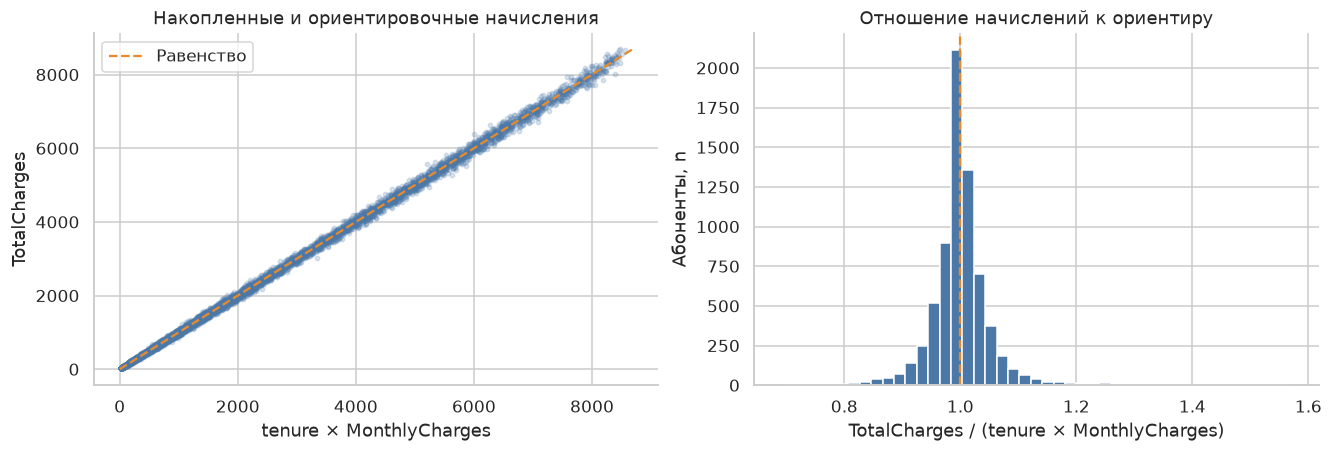

In [5]:
charge_check = df.loc[
    df["TotalCharges"].notna() & df["tenure"].gt(0),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"],
].copy()
charge_check["reference_total"] = charge_check["tenure"] * charge_check["MonthlyCharges"]
charge_check["ratio"] = charge_check["TotalCharges"] / charge_check["reference_total"]
charge_check["difference"] = charge_check["TotalCharges"] - charge_check["reference_total"]
charge_check["relative_difference_pct"] = (charge_check["ratio"] - 1) * 100
display(charge_check["ratio"].describe(percentiles=[.05, .25, .5, .75, .95]).to_frame())
within_ten_pct = charge_check["ratio"].between(.9, 1.1)
print(f"В пределах ±10%: {within_ten_pct.sum()} / {len(charge_check)} = {within_ten_pct.mean():.2%}")
extreme_rows = charge_check["relative_difference_pct"].abs().nlargest(4).index
display(charge_check.loc[extreme_rows].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].scatter(charge_check["reference_total"], charge_check["TotalCharges"], s=8, alpha=.2, color=BLUE)
limit = max(charge_check["reference_total"].max(), charge_check["TotalCharges"].max())
axes[0].plot([0, limit], [0, limit], linestyle="--", color=ORANGE, label="Равенство")
axes[0].set(xlabel="tenure × MonthlyCharges", ylabel="TotalCharges", title="Накопленные и ориентировочные начисления")
axes[0].legend()
axes[1].hist(charge_check["ratio"], bins=45, color=BLUE)
axes[1].axvline(1, color=ORANGE, linestyle="--")
axes[1].set(xlabel="TotalCharges / (tenure × MonthlyCharges)", ylabel="Абоненты, n", title="Отношение начислений к ориентиру")
plt.show()

Диагностика охватывает 7 032 строки. Медиана отношения равна 1,000;
у 94,58% клиентов расхождение укладывается в ±10%.
Значит, накопленные начисления согласуются с ожидаемым порядком величины.

Есть отклонения, особенно заметные в относительном выражении при
малом сроке обслуживания. Они требуют предметной интерпретации:
изменения цены или состава услуг в CSV не наблюдаются. Само
расхождение с произведением не доказывает ошибку. Значения не
перезаписываются этим произведением, строки не удаляются.

## 3. Целевая переменная

Сначала считаем размеры и доли классов. Во всех последующих сравнениях
доля оттока — это число `Churn = Yes`, делённое на число клиентов
внутри рассматриваемой группы.

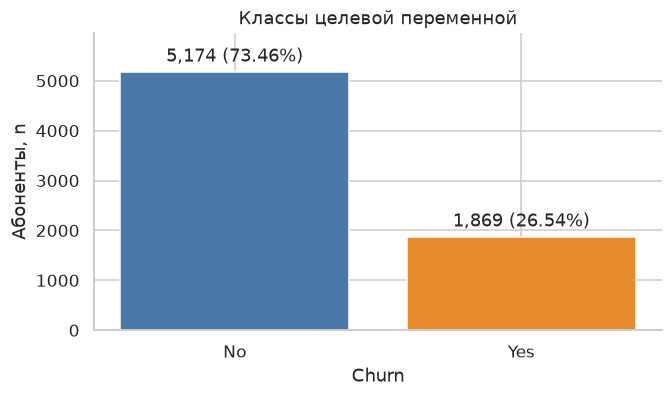

In [6]:
class_counts = df["Churn"].value_counts().reindex(["No", "Yes"])
overall_churn_pct = df["Churn"].eq("Yes").mean() * 100
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
bars = ax.bar(class_counts.index, class_counts.values, color=[BLUE, ORANGE])
ax.bar_label(bars, labels=[f"{n:,} ({n / len(df):.2%})" for n in class_counts], padding=4)
ax.set(xlabel="Churn", ylabel="Абоненты, n", title="Классы целевой переменной", ylim=(0, class_counts.max() * 1.15))
plt.show()

Ушли 1 869 из 7 043 клиентов — 26,54%, остались 5 174 — 73,46%.
Предсказание «все остаются» уже даст Accuracy 73,46%, поэтому одной
Accuracy недостаточно. При моделировании нужно оценивать обнаружение
оттока и качество вероятностей; выбор основной метрики и разбиения
ещё обсуждается в журнале. Балансировка на этапе EDA не выполняется.

## 4. Распределения признаков

### 4.1. Числовые признаки и выбросы

`describe`, гистограммы и boxplot строятся на исходных значениях.
В расчётах `TotalCharges` используются 7 032 известных значения;
для двух остальных признаков — все 7 043 строки.

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


,lower,upper,outside_n
feature,,,
tenure,-60.00,124.00,0
MonthlyCharges,-46.02,171.38,0
TotalCharges,-4688.48,8884.67,0


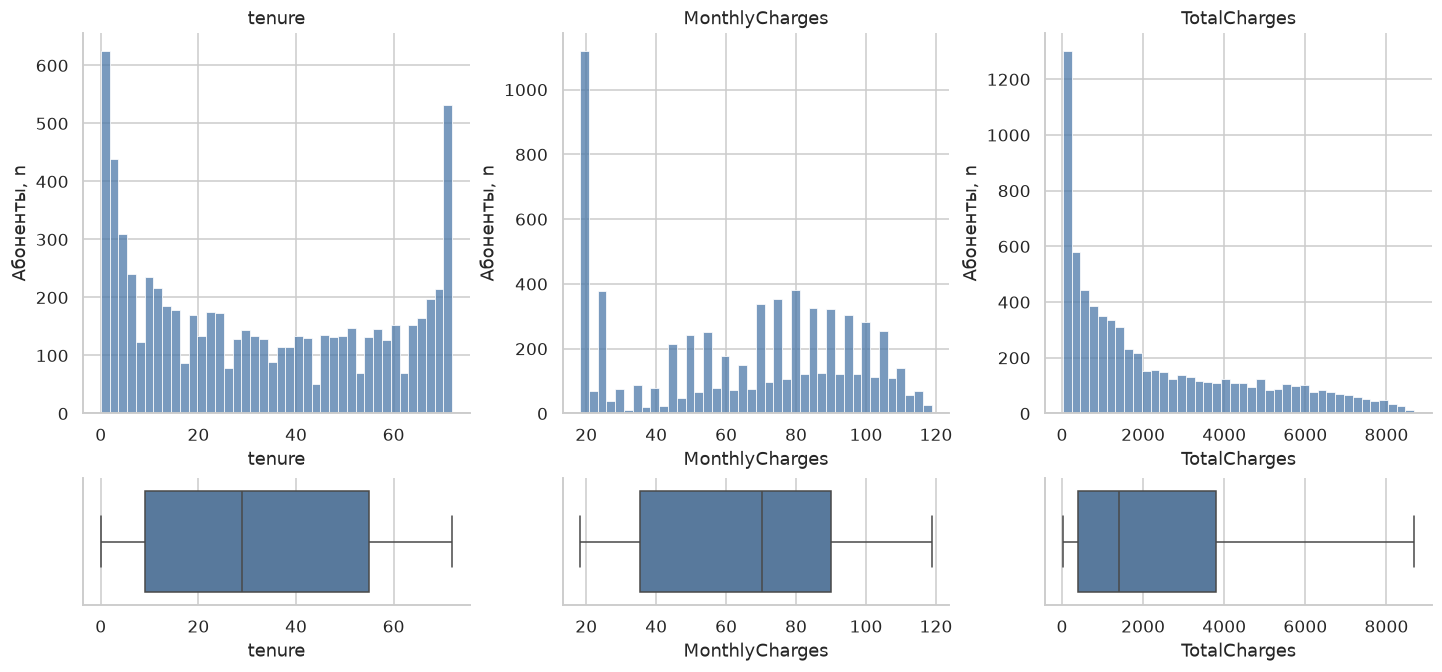

In [7]:
display(df[NUMERIC].describe().round(2))
iqr_rows = []
for col in NUMERIC:
    values = df[col].dropna()
    q1, q3 = values.quantile([.25, .75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    iqr_rows.append({"feature": col, "lower": lower, "upper": upper,
                     "outside_n": int((~values.between(lower, upper)).sum())})
display(pd.DataFrame(iqr_rows).set_index("feature").round(2))

fig, axes = plt.subplots(2, 3, figsize=(13, 6), layout="constrained", height_ratios=[3, 1])
for i, col in enumerate(NUMERIC):
    sns.histplot(data=df, x=col, bins=40, ax=axes[0, i], color=BLUE)
    axes[0, i].set(title=col, xlabel=col, ylabel="Абоненты, n")
    sns.boxplot(data=df, x=col, ax=axes[1, i], color=BLUE)
    axes[1, i].set(xlabel=col, ylabel="")
plt.show()

`tenure` лежит в диапазоне 0–72 месяца, медиана — 29 месяцев;
заметны скопления клиентов с малым и большим сроком обслуживания.
Месячные начисления лежат в диапазоне 18,25–118,75, медиана — 70,35.
`TotalCharges` имеет длинный правый хвост: это накопительная сумма,
и большой счёт может объясняться сроком и стоимостью услуг.

На всей выборке для каждого из трёх признаков наблюдений вне
границ 1,5 IQR нет. Это результат конкретной проверки, а не доказательство
отсутствия любых ошибок. Усы boxplot внутри отдельных групп могут
быть другими. Автоматическая фильтрация по IQR не применяется.

### 4.2. Частоты категорий

Показываем каждый категориальный признак один раз. `SeniorCitizen`
представлен как `No`/`Yes`; `Churn` уже рассмотрен отдельно,
идентификатор не включается.

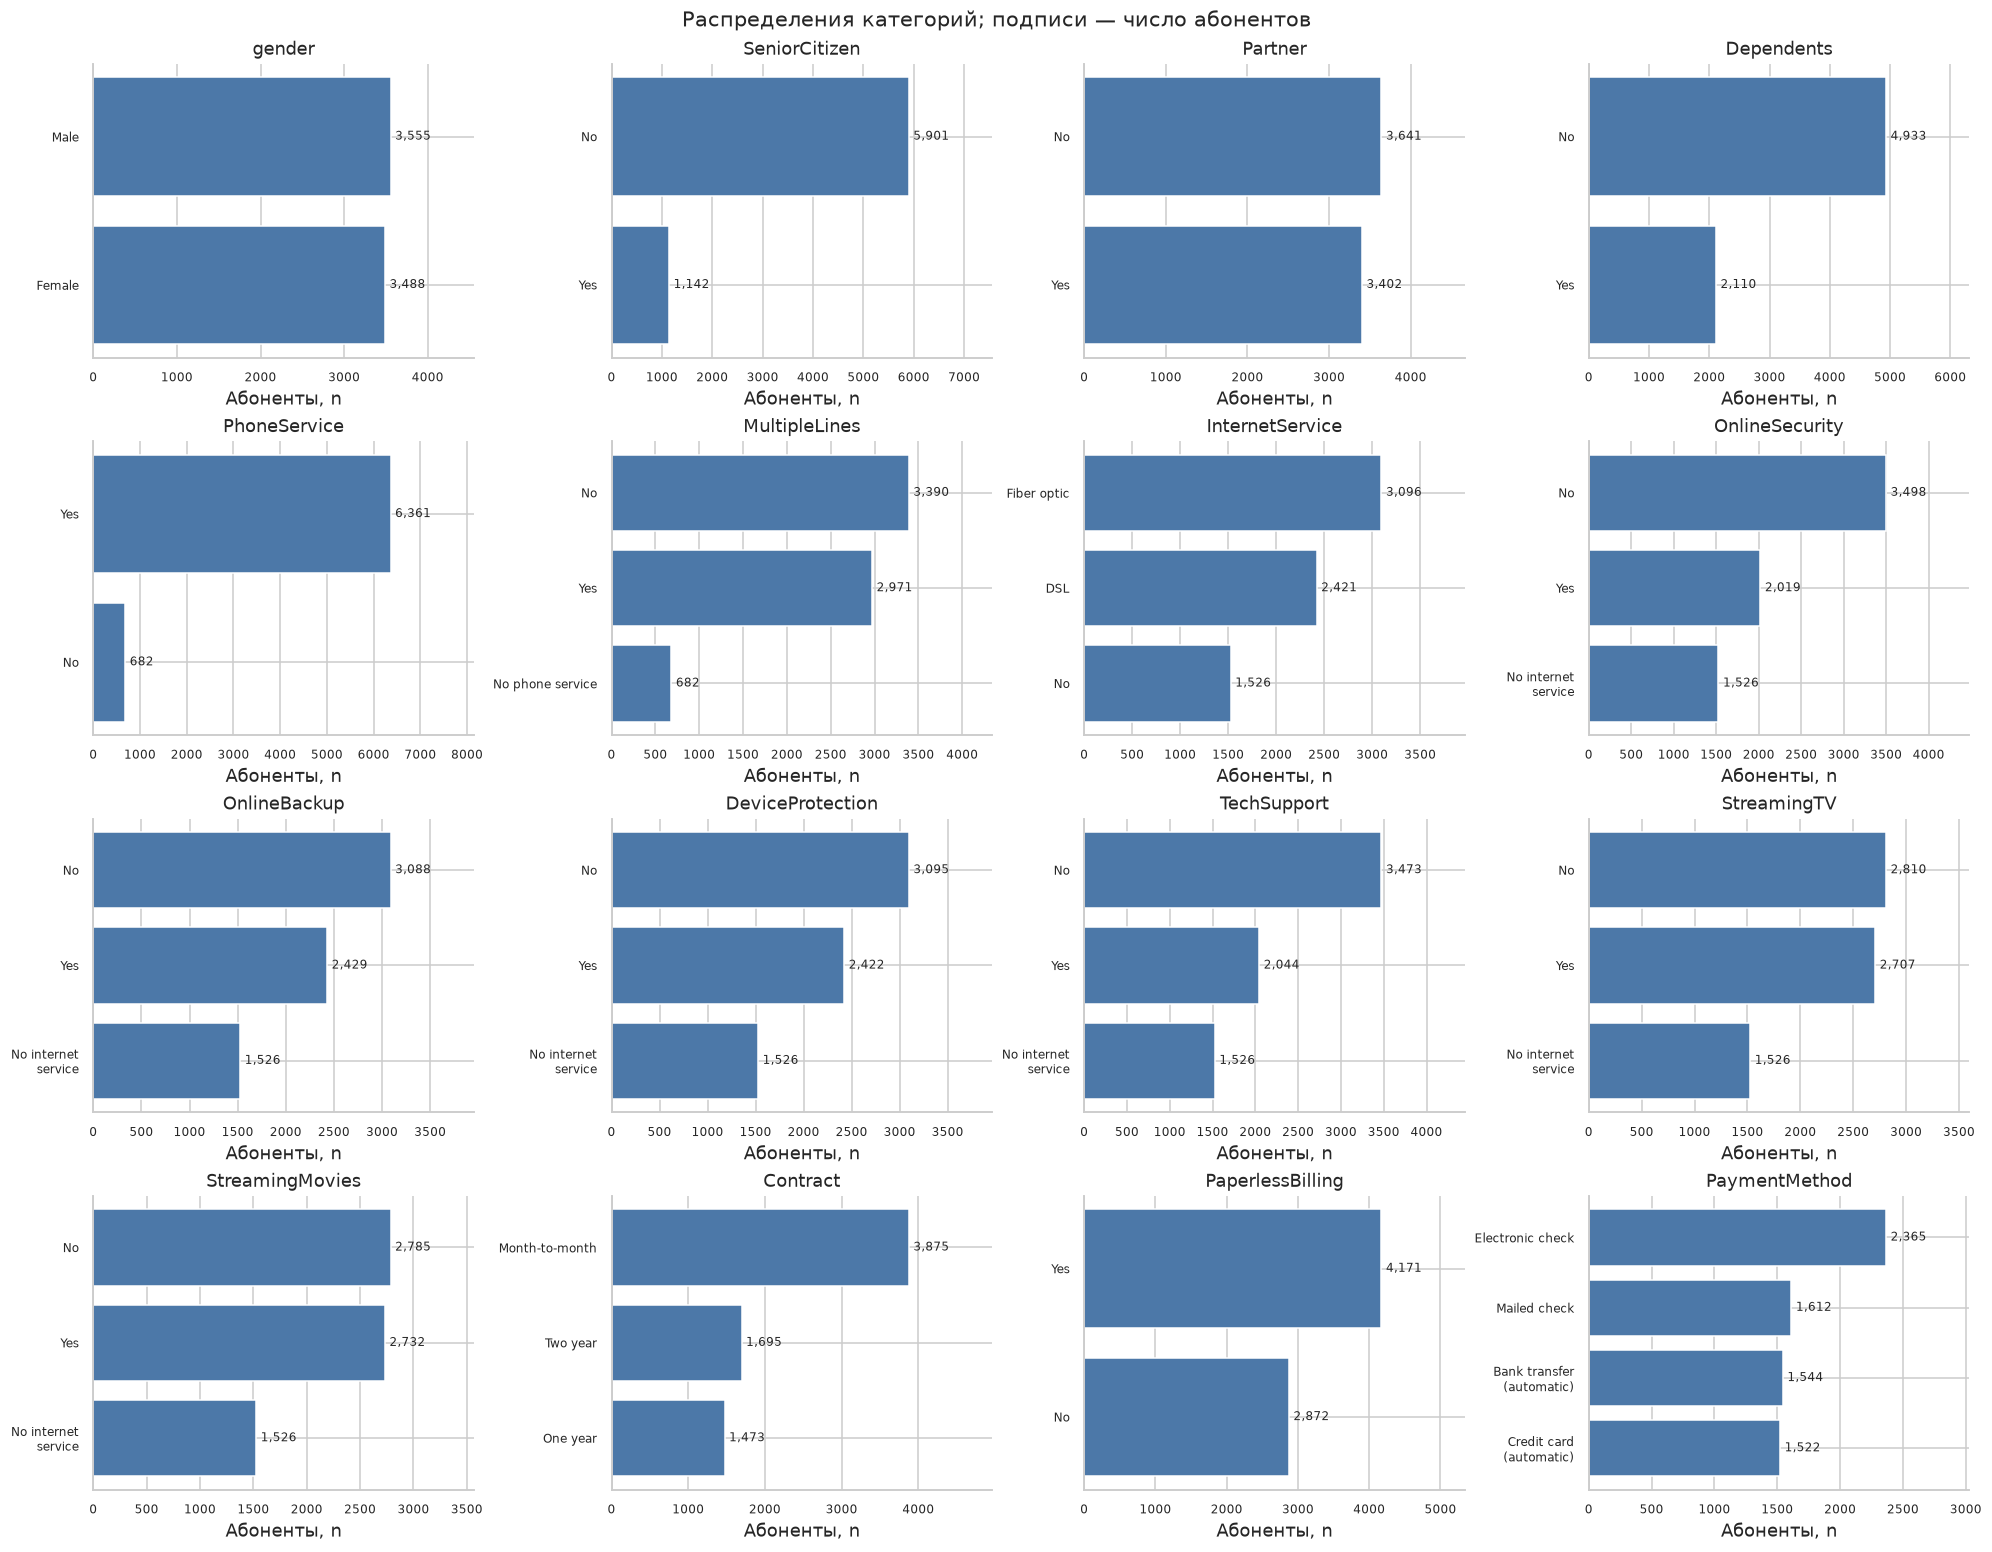

In [8]:
categorical_cols = [col for col in df.columns if col not in ["customerID", "Churn", *NUMERIC]]
fig, axes = plt.subplots(4, 4, figsize=(18, 14), layout="constrained")
for ax, col in zip(axes.flat, categorical_cols):
    counts = df[col].value_counts()
    positions = np.arange(len(counts))
    bars = ax.barh(positions, counts.values, color=BLUE)
    ax.set_yticks(positions, [fill(str(label), 17) for label in counts.index])
    ax.bar_label(bars, labels=[f"{n:,}" for n in counts], padding=3, fontsize=8)
    ax.invert_yaxis()
    ax.set(title=col, xlabel="Абоненты, n", xlim=(0, counts.max() * 1.28))
    ax.tick_params(labelsize=8)
fig.suptitle("Распределения категорий; подписи — число абонентов", fontsize=14)
plt.show()

Пол представлен примерно поровну. Пожилых клиентов 1 142 (16,2%),
интернет подключён у 5 517 (78,3%). Помесячных договоров 3 875 (55,0%),
годовых — 1 473, двухлетних — 1 695. Способ `Electronic check`
используют 2 365 абонентов (33,6%).

Размеры категорий различаются. Далее сравниваются доли оттока внутри
каждой категории, а не только абсолютные количества ушедших.

## 5. Связь признаков с оттоком

### 5.1. Числовые признаки по группам Churn

,clients_n,tenure,MonthlyCharges,TotalCharges,known_TotalCharges_n
Churn,,,,,
No,5174,38.0,64.425,1683.60,5163
Yes,1869,10.0,79.650,703.55,1869


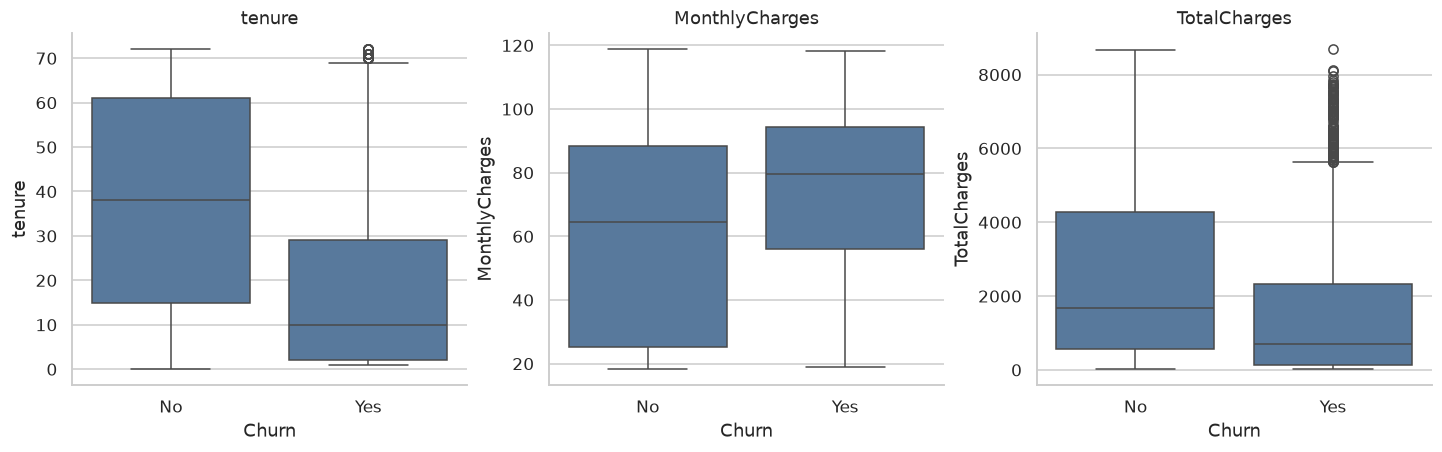

In [9]:
medians = df.groupby("Churn")[NUMERIC].median()
medians.insert(0, "clients_n", df.groupby("Churn").size())
medians["known_TotalCharges_n"] = df.groupby("Churn")["TotalCharges"].count()
display(medians.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(data=df, x="Churn", y=col, order=["No", "Yes"], ax=ax, color=BLUE)
    ax.set(title=col, xlabel="Churn", ylabel=col)
plt.show()

Медианный срок обслуживания у ушедших — 10 месяцев, у оставшихся — 38.
Медианные месячные начисления — 79,650 против 64,425;
накопленные — 703,550 против 1 683,600. Последняя медиана у оставшихся
рассчитана по 5 163 известным суммам, без подстановки 11 нулей.

Распределения перекрываются. Отдельные различия по сроку и стоимости
ещё не доказывают, что именно их сочетание — главный сегмент риска;
это гипотеза для совместного анализа и модели.

### 5.2. Доли оттока по интервалам срока и месячной платы

Границы интервалов заданы для описания данных, не подбираются по метрике
модели. Группа `0–12` включает и `tenure = 0`; границы стоимости подписаны
с указанием включённой правой границы. Это диапазоны начислений,
а не названия реальных тарифов.

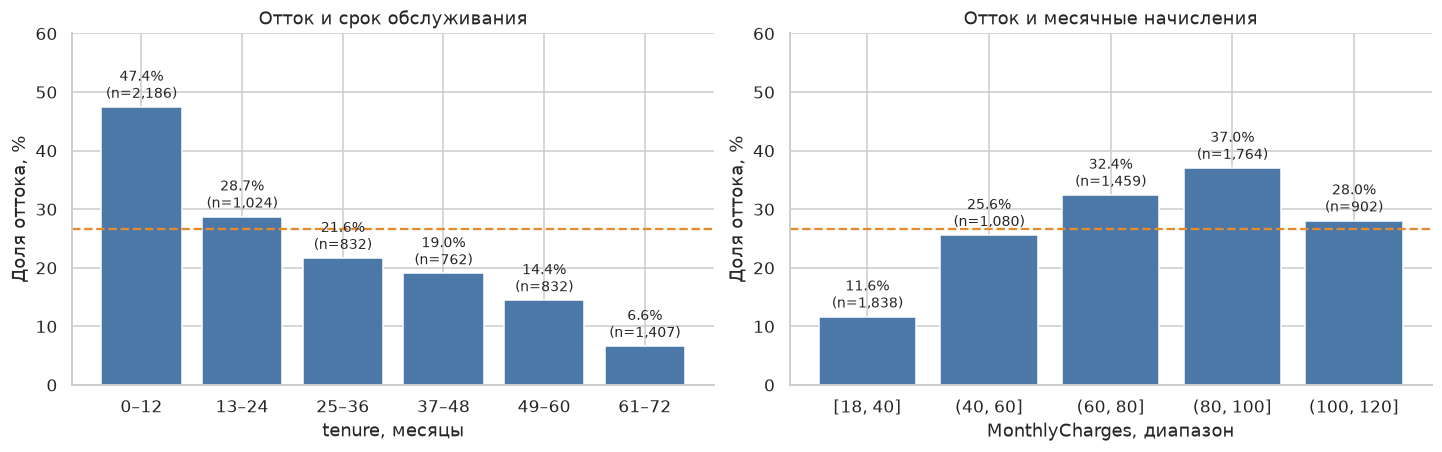

In [10]:
def churn_summary(frame, by):
    result = (
        frame.assign(_churned=frame["Churn"].eq("Yes"))
        .groupby(by, observed=True, dropna=False)["_churned"]
        .agg(n="size", churned="sum")
    )
    result["churn_pct"] = result["churned"] / result["n"] * 100
    return result


segments = df.assign(
    tenure_group=pd.cut(df["tenure"], bins=[0, 12, 24, 36, 48, 60, 72],
                        labels=["0–12", "13–24", "25–36", "37–48", "49–60", "61–72"],
                        include_lowest=True),
    charges_group=pd.cut(df["MonthlyCharges"], bins=[18, 40, 60, 80, 100, 120],
                         labels=["[18, 40]", "(40, 60]", "(60, 80]", "(80, 100]", "(100, 120]"],
                         include_lowest=True),
)
tenure_summary = churn_summary(segments, "tenure_group")
charges_summary = churn_summary(segments, "charges_group")
assert segments[["tenure_group", "charges_group"]].notna().all().all()
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for ax, table, title, xlabel in [
    (axes[0], tenure_summary, "Отток и срок обслуживания", "tenure, месяцы"),
    (axes[1], charges_summary, "Отток и месячные начисления", "MonthlyCharges, диапазон"),
]:
    bars = ax.bar(table.index.astype(str), table["churn_pct"], color=BLUE)
    ax.bar_label(bars, labels=[f"{r:.1f}%\n(n={n:,})" for r, n in zip(table["churn_pct"], table["n"])], padding=3, fontsize=9)
    ax.axhline(overall_churn_pct, linestyle="--", color=ORANGE)
    ax.set(title=title, xlabel=xlabel, ylabel="Доля оттока, %", ylim=(0, 60))
plt.show()

В группе 0–12 месяцев отток составляет 47,44% (1 037 / 2 186),
в группе 61–72 — 6,61% (93 / 1 407). На выбранных 12-месячных
интервалах доля последовательно снижается; отдельный резкий перелом
около 30 месяцев, предположенный в исходной работе Катрины,
такое разбиение не подтверждает. Оно также не доказывает отсутствие
более сложной формы связи.

По месячной плате зависимость не строго возрастающая: при начислениях
(80, 100] отток 37,02% (653 / 1 764), при (100, 120] — 28,05%
(253 / 902). Различия могут быть связаны с составом услуг, договорами
и сроком обслуживания. По этим снимкам нельзя оценивать вероятность
ухода одного и того же клиента на каждом месяце жизни.

### 5.3. Доли оттока по всем категориям

Для каждой категории показываем процент и размер группы `n`.
Пунктир — общая доля оттока 26,54%. Одинаковая шкала позволяет
сравнивать панели; сами эти сравнения остаются одномерными.

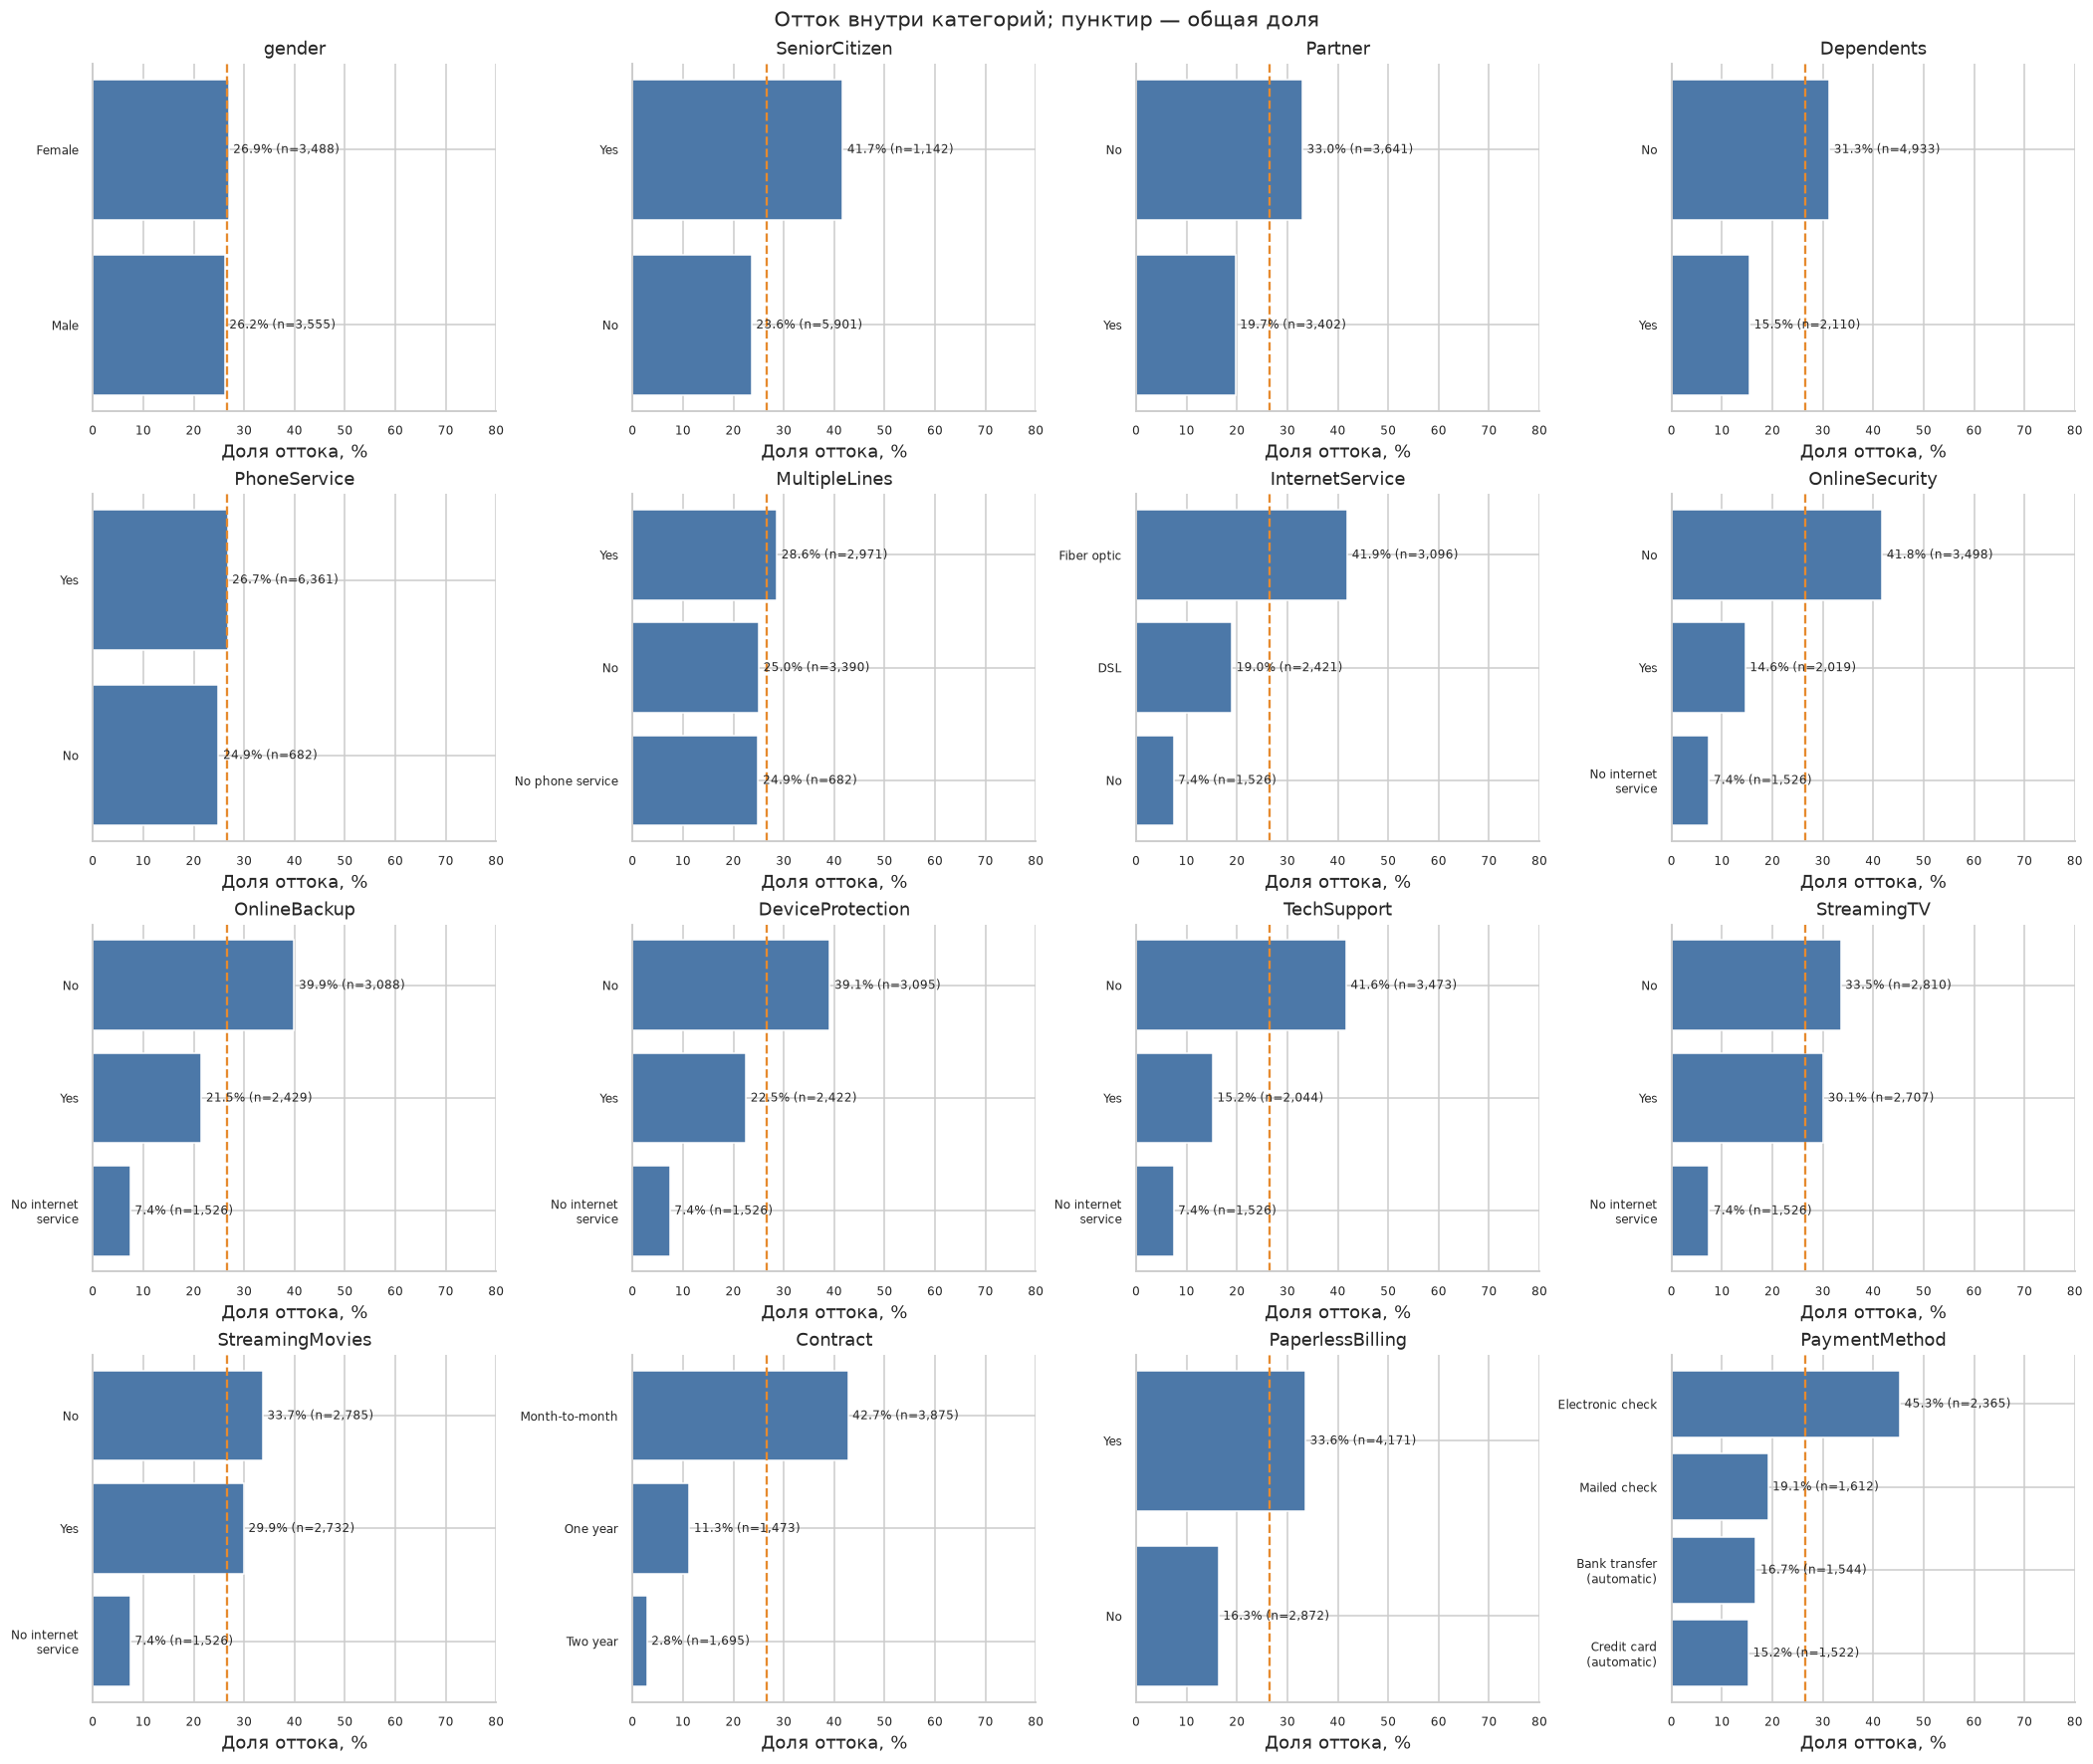

In [11]:
category_churn = {col: churn_summary(df, col) for col in categorical_cols}
fig, axes = plt.subplots(4, 4, figsize=(19, 16), layout="constrained")
for ax, col in zip(axes.flat, categorical_cols):
    table = category_churn[col].sort_values("churn_pct", ascending=False)
    positions = np.arange(len(table))
    bars = ax.barh(positions, table["churn_pct"], color=BLUE)
    ax.set_yticks(positions, [fill(str(label), 17) for label in table.index])
    ax.bar_label(bars, labels=[f"{r:.1f}% (n={n:,})" for r, n in zip(table["churn_pct"], table["n"])], padding=3, fontsize=8)
    ax.axvline(overall_churn_pct, color=ORANGE, linestyle="--")
    ax.invert_yaxis()
    ax.set(title=col, xlabel="Доля оттока, %", xlim=(0, 80))
    ax.tick_params(labelsize=8)
fig.suptitle("Отток внутри категорий; пунктир — общая доля", fontsize=14)
plt.show()

Помесячным договорам соответствует 42,71% оттока (1 655 / 3 875),
годовым — 11,27% (166 / 1 473), двухлетним — 2,83% (48 / 1 695).
У `Fiber optic` — 41,89% (1 297 / 3 096), у `DSL` — 18,96%
(459 / 2 421), без интернета — 7,40% (113 / 1 526).
У `Electronic check` — 45,29% (1 071 / 2 365).

Отток различается также по `TechSupport`, `OnlineSecurity`,
`SeniorCitizen`, `Partner`, `Dependents` и `PaperlessBilling`.
По полу различие невелико: 26,92% у женщин и 26,16% у мужчин.
Категория `No internet service` не объединялась с `No`.

Здесь нет оценки самостоятельного влияния признаков: группа без
поддержки может отличаться одновременно сроком, стоимостью и договором.
Поэтому формулировки «поддержка защищает» или «способ оплаты вызывает уход»
этим анализом не обоснованы.

## 6. Совместные факторы

### 6.1. Интернет и месячная плата

Проверяем, отличаются ли начисления между категориями интернета,
у которых выше уже наблюдались разные доли оттока.

,n,median,q25,q75
InternetService,,,,
DSL,2421,56.150,46.20,69.90
Fiber optic,3096,91.675,80.55,101.15
No,1526,20.150,19.70,20.90


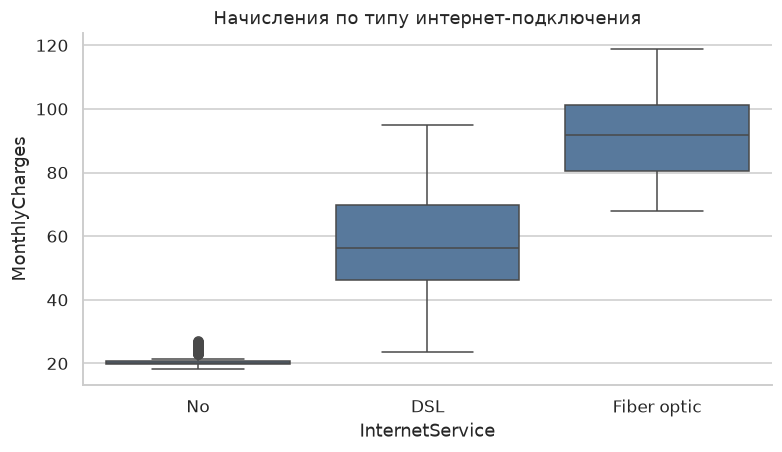

In [12]:
internet_price = df.groupby("InternetService")["MonthlyCharges"].agg(
    n="size", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75)
)
display(internet_price.round(3))
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", order=["No", "DSL", "Fiber optic"], color=BLUE, ax=ax)
ax.set(title="Начисления по типу интернет-подключения", xlabel="InternetService", ylabel="MonthlyCharges")
plt.show()

Медианная месячная плата у клиентов без интернета — 20,15,
с DSL — 56,15, с Fiber optic — 91,675. Категории интернета
различаются и по стоимости, и по оттоку. Значит, интерпретировать
разницу по `InternetService` отдельно от `MonthlyCharges` было бы
преждевременно. Даже такое сравнение не показывает, что высокая
цена является причиной ухода.

### 6.2. Способ оплаты внутри типа договора

Сначала смотрим состав групп оплаты, затем их отток при одинаковом
типе договора. На тепловой карте каждая ячейка содержит долю и размер
своей группы; это не сравнение абсолютного числа ушедших.

,n,tenure_median,monthly_median,month_to_month_pct
PaymentMethod,,,,
Electronic check,2365,18.0,80.55,78.22
Mailed check,1612,15.0,34.70,55.40
Bank transfer (automatic),1544,48.0,73.10,38.15
Credit card (automatic),1522,47.0,73.03,35.68


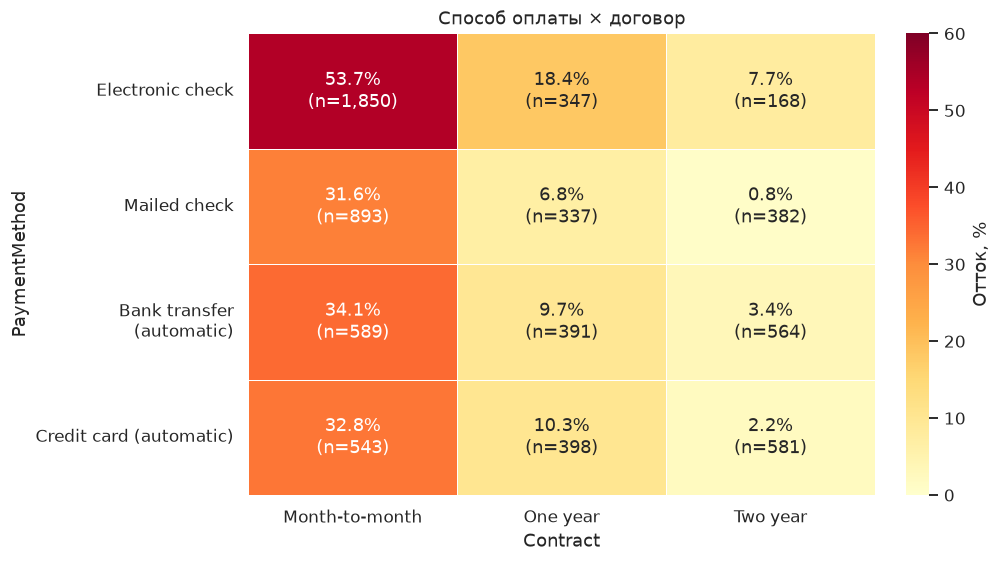

In [13]:
payment_profile = df.groupby("PaymentMethod").agg(
    n=("Churn", "size"), tenure_median=("tenure", "median"),
    monthly_median=("MonthlyCharges", "median"),
    month_to_month_pct=("Contract", lambda s: s.eq("Month-to-month").mean() * 100),
).reindex(PAYMENT_ORDER)
display(payment_profile.round(2))


def joint_churn_heatmap(table, row_order, col_order, ax, title):
    rates = table["churn_pct"].unstack().reindex(index=row_order, columns=col_order)
    sizes = table["n"].unstack().reindex(index=row_order, columns=col_order)
    annotations = pd.DataFrame("", index=rates.index, columns=rates.columns)
    for row in rates.index:
        for col in rates.columns:
            if pd.notna(rates.loc[row, col]):
                n = int(sizes.loc[row, col])
                small = " *" if n < 100 else ""
                annotations.loc[row, col] = f"{rates.loc[row, col]:.1f}%\n(n={n:,}){small}"
    sns.heatmap(rates, annot=annotations, fmt="", vmin=0, vmax=60, cmap="YlOrRd",
                linewidths=.5, cbar_kws={"label": "Отток, %"}, ax=ax)
    ax.set_title(title)
    ax.set_yticklabels([fill(str(label), 24) for label in rates.index], rotation=0)
    ax.set_xticklabels(rates.columns, rotation=0)


payment_contract = churn_summary(df, ["PaymentMethod", "Contract"])
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
joint_churn_heatmap(payment_contract, PAYMENT_ORDER, CONTRACT_ORDER, ax, "Способ оплаты × договор")
ax.set(xlabel="Contract", ylabel="PaymentMethod")
plt.show()

Среди клиентов `Electronic check` помесячные договоры имеют 78,22%,
медианный срок обслуживания — 18 месяцев, месячная плата — 80,55.
У `Mailed check` медианный срок ещё меньше (15 месяцев), но плата
ниже — 34,70: одного срока для описания различий недостаточно.

Внутри каждого типа договора у `Electronic check` доля оттока выше,
чем у остальных способов: 53,73% (994 / 1 850) на помесячном,
18,44% (64 / 347) на годовом и 7,74% (13 / 168) на двухлетнем.
Тип договора не объясняет всю наблюдаемую разницу. Но это ещё
не независимый эффект оплаты: другие характеристики не уравнены.
Небольшое число уходов в отдельных ячейках, например 3 из 382
для `Two year + Mailed check`, ограничивает точность процентов.

### 6.3. Тип договора при сопоставимом сроке обслуживания

Сравниваем договоры внутри тех же интервалов `tenure`.
Звёздочкой отмечены группы меньше 100 клиентов: отсутствие событий
в небольшой группе не означает нулевого риска.

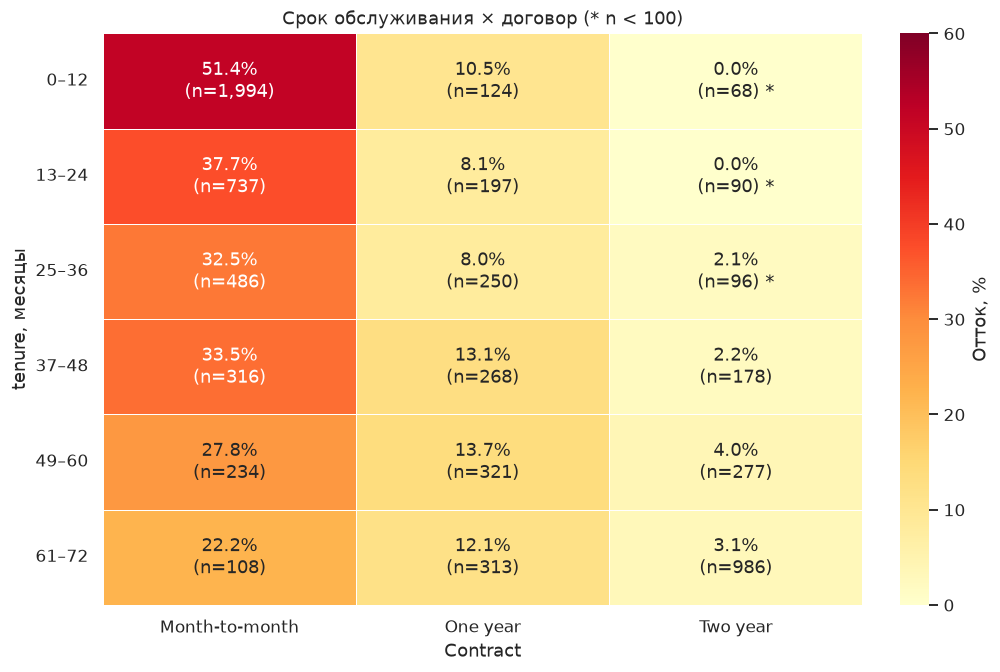

In [14]:
tenure_contract = churn_summary(segments, ["tenure_group", "Contract"])
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
joint_churn_heatmap(tenure_contract, segments["tenure_group"].cat.categories, CONTRACT_ORDER,
                    ax, "Срок обслуживания × договор (* n < 100)")
ax.set(xlabel="Contract", ylabel="tenure, месяцы")
plt.show()

Во всех шести интервалах `tenure` доля оттока максимальна у
помесячных и минимальна у двухлетних договоров. Наблюдаемая
разница не исчезает при таком приближённом учёте срока обслуживания.

В первых двух интервалах у двухлетних договоров нет уходов,
но группы содержат только 68 и 90 клиентов. Их фактический риск
не установлен равным нулю. Разбиение на интервалы не заменяет
совместную модель и не устанавливает причинное влияние договора.

## 7. Связи между признаками

### 7.1. Pearson и Spearman

Pearson описывает линейную, Spearman — монотонную связь.
Пропуски исключаются только для соответствующей пары:
с `TotalCharges` доступно 7 032 наблюдения, без него — 7 043.

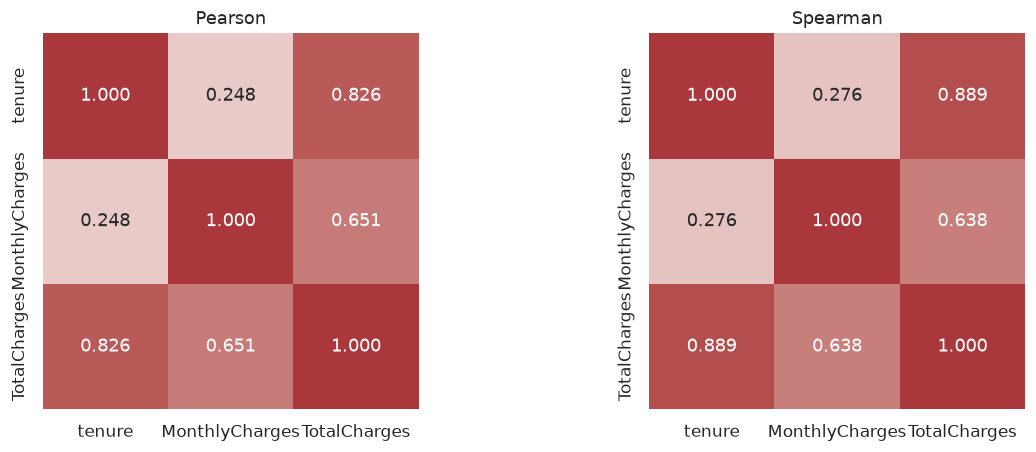

In [15]:
pearson = df[NUMERIC].corr(method="pearson")
spearman = df[NUMERIC].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, matrix, title in [(axes[0], pearson, "Pearson"), (axes[1], spearman, "Spearman")]:
    sns.heatmap(matrix, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1,
                square=True, cbar=False, ax=ax)
    ax.set_title(title)
plt.show()

У `tenure` и `TotalCharges` Pearson ≈ 0,826, Spearman ≈ 0,889.
У `MonthlyCharges` и `TotalCharges` — соответственно ≈ 0,651 и ≈ 0,638.
Начисления и срок связаны, что может затруднять интерпретацию
коэффициентов линейной модели. Но высокая парная корреляция сама
по себе не показывает, что один признак бесполезен. Проверка
состава признаков и регуляризации относится к этапу моделирования.

### 7.2. φk для смешанных типов

Числовыми явно объявлены только `tenure`, `MonthlyCharges`, `TotalCharges`;
для них заданы 10 равных по ширине интервалов. `SeniorCitizen`
обрабатывается как категория. `customerID` исключён.

φk находится в диапазоне 0–1 и не показывает направление связи.
Он зависит в том числе от разбиения числовых значений. Строковые
названия `Contract` не объявляют автоматически порядок договоров.
Попарная связь с целью не равна важности признака в модели.
Подробности параметров — в [документации phik](https://phik.readthedocs.io/en/latest/phik.html#phik.phik.phik_matrix).

`NaN` не заполняются: при `dropna=True` пропуски исключаются из
соответствующих пар, а не из всей таблицы.

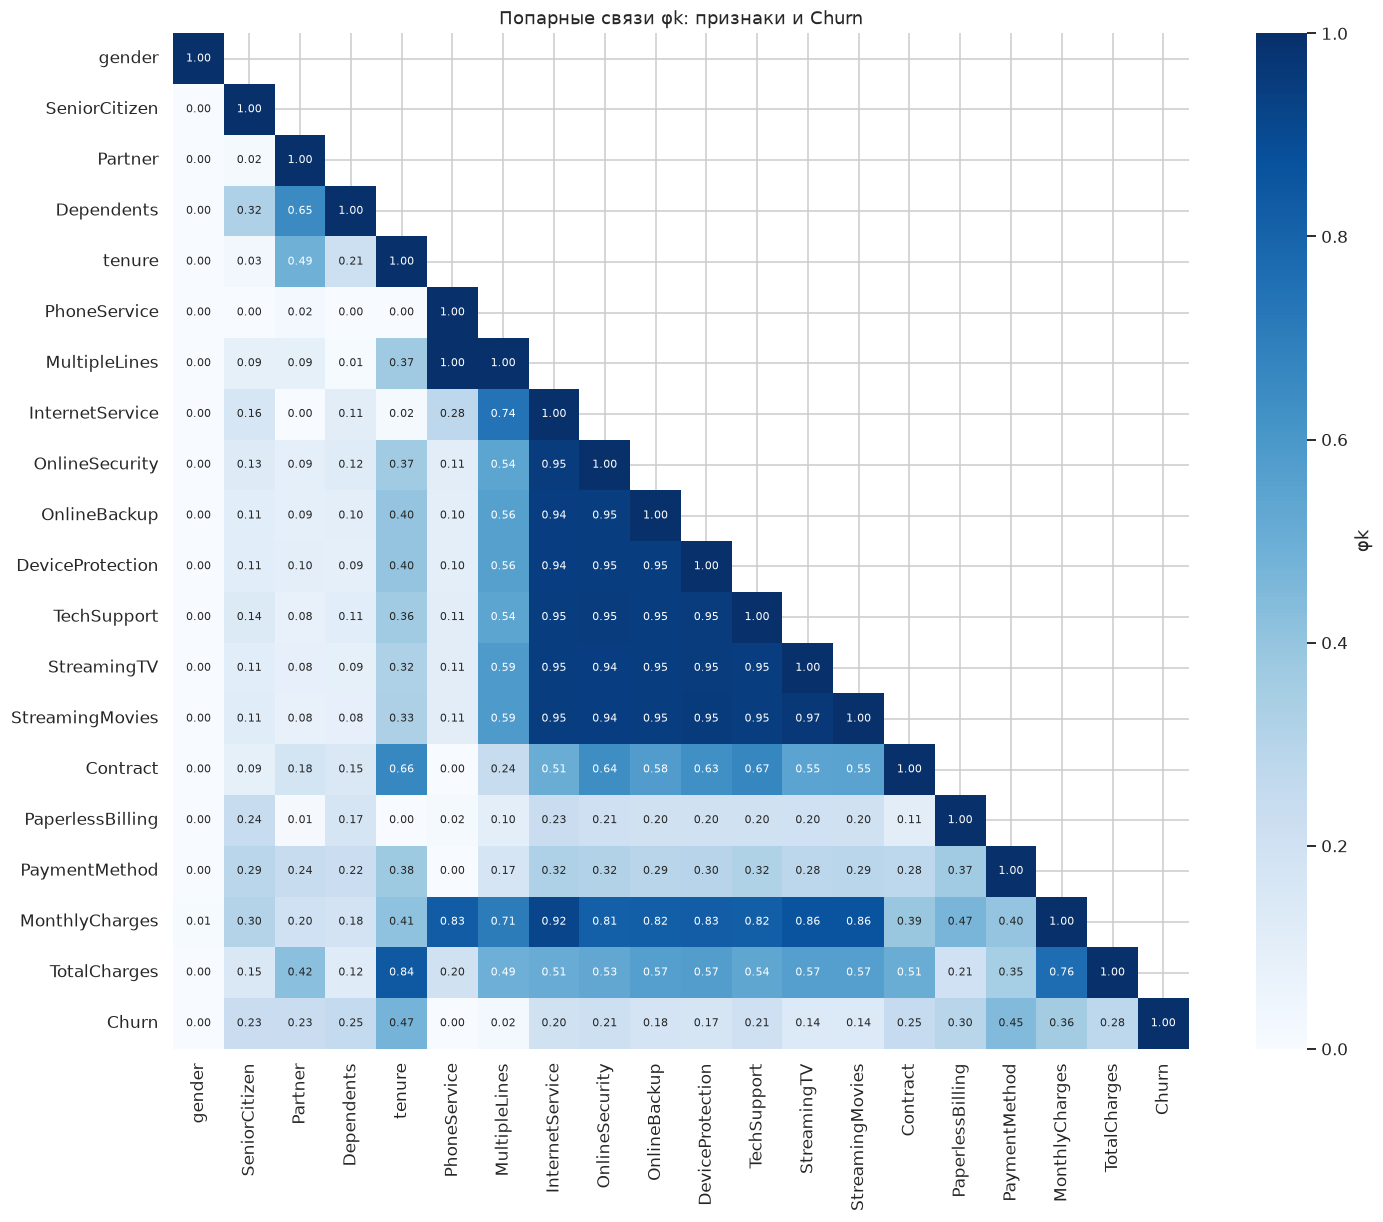

,phi_k_with_Churn
tenure,0.474
PaymentMethod,0.449
MonthlyCharges,0.360
PaperlessBilling,0.296
TotalCharges,0.281
Dependents,0.254
Contract,0.252
SeniorCitizen,0.233


In [16]:
phik_matrix = df.drop(columns="customerID").phik_matrix(
    interval_cols=NUMERIC, bins=10, quantile=False, dropna=True, njobs=1,
)
mask = np.triu(np.ones(phik_matrix.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11), layout="constrained")
sns.heatmap(phik_matrix, mask=mask, vmin=0, vmax=1, cmap="Blues",
            annot=True, fmt=".2f", annot_kws={"fontsize": 7}, square=True,
            cbar_kws={"label": "φk"}, ax=ax)
ax.set_title("Попарные связи φk: признаки и Churn")
plt.show()
display(phik_matrix["Churn"].drop("Churn").sort_values(ascending=False).head(8).to_frame("phi_k_with_Churn").round(3))

Наибольшие рассчитанные связи с `Churn` — у `tenure` (≈ 0,47),
`PaymentMethod` (≈ 0,45) и `MonthlyCharges` (≈ 0,36).
Сильные связи между самими признаками включают `tenure`–`TotalCharges`
(≈ 0,84), `Contract`–`tenure` (≈ 0,66) и зависимости основных
и дополнительных интернет-услуг.

Коэффициент `Contract`–`Churn` здесь около 0,25, хотя доли оттока
по договорам сильно различаются. Матрица дополняет группировки,
а не заменяет их. Низкий либо высокий φk не является достаточным
основанием для удаления признака или утверждения о причине ухода.

## 8. Итоги и передача в моделирование

В таблице приведены наблюдения, варианты подготовки и проверяемые
гипотезы. Это предложения для обсуждения, а не утверждённые решения.
Основания находятся в соответствующих разделах выше.

| Наблюдение | Подготовка данных / статус | Что проверить в модели |
|---|---|---|
| 11 неизвестных `TotalCharges`, все при `tenure = 0` | В EDA оставлены `NaN`; нулевое заполнение для первого бейзлайна предложено в журнале | Чувствительность к обработке этой группы на обучающей части |
| Полных дублей и повторных ID нет; у разных клиентов есть одинаковые профили | Строки сохранены; `customerID` исключается из признаков | Ограничения предсказуемости при одинаковых наблюдаемых характеристиках и разных исходах |
| Отток 26,54%; Accuracy постоянного прогноза 73,46% | Балансировка не выполнялась, основная метрика ещё не согласована | ROC-AUC, PR-AUC и метрики обнаружения оттока; качество и калибровка вероятностей |
| По сроку доля оттока снижается, по месячной плате немонотонна | Исходные числовые признаки сохранены; интервалы используются только для EDA | Нелинейность и сочетание `tenure` с `MonthlyCharges` |
| По договорам различия сохраняются внутри интервалов срока | Категории договора сохранены | Дополнительная полезность `Contract` с учётом срока |
| `Electronic check` отличается и внутри каждого типа договора | Способ оплаты сохранён как категория | Совместная полезность оплаты, договора, срока и стоимости |
| Интернет связан одновременно со стоимостью и оттоком | Основные и дополнительные услуги сохранены раздельно | Какие связи сохраняются при совместном учёте признаков |
| Специальные категории услуг повторяют отсутствие основной услуги | В EDA не объединены с `No`; окончательное кодирование не выбрано | Варианты кодирования и избыточность, без потери смысла категорий |
| Накопленные начисления связаны со сроком и текущей платой | Нет автоматического удаления строк или коррелирующих столбцов | Полезность `TotalCharges` дополнительно к сроку и плате; регуляризация |
| Распределения групп перекрываются, есть маленькие подгруппы | Проценты сопровождаются `n` | Устойчивость качества и выводов на валидации |

### Ограничения

- Это снимок данных одного набора, а не продольная история клиентов.
  Связь срока с оттоком не является оценкой индивидуального риска по времени.
- Нет истории изменения тарифов, отдельных платежей и причин ухода.
  Наблюдаемые ассоциации не устанавливают причинность.
- Совместные группировки учитывают только часть признаков; остаются
  различия состава групп. Небольшие группы ограничивают точность долей.
- При подготовке модели разбиение выполняется до обучения преобразований.
  Статистики заполнения, масштабирование и кодирование оцениваются
  только на обучающей части внутри Pipeline. Финальный тест не используется
  для выбора способов обработки или гиперпараметров.
- EDA изучает весь доступный набор: будущая тестовая часть уже участвовала
  в описательном анализе. Оценка на ней не является полностью независимой
  проверкой всех исследовательских решений; это ограничение нужно раскрыть.

Бейзлайн в этот ноутбук не добавлен. Основная метрика, параметры разбиения,
кодирование и окончательная обработка пропусков требуют обсуждения команды
и фиксации в [журнале решений](../docs/decisions.md).

## 9. Контроль выполнения

Проверяем сохранение исходных строк и пропусков, полноту группировок
и корректность рассчитанных матриц. Это проверки результата данного EDA,
а не обучение или оценка модели.

In [17]:
assert df.shape == raw.shape == (7043, 21)
assert df["customerID"].equals(raw["customerID"])
pd.testing.assert_frame_equal(df.drop(columns="SeniorCitizen"), raw.drop(columns="SeniorCitizen"))
assert int(df["TotalCharges"].isna().sum()) == 11
assert int(df["Churn"].eq("Yes").sum()) == 1869
assert int(tenure_summary["n"].sum()) == int(charges_summary["n"].sum()) == len(df)
assert int(payment_contract["n"].sum()) == int(tenure_contract["n"].sum()) == len(df)
assert all(int(table["n"].sum()) == len(df) for table in category_churn.values())
assert service_checks[["absent_main_wrong_status_n", "present_main_special_status_n"]].eq(0).all().all()
assert phik_matrix.index.equals(phik_matrix.columns)
assert np.allclose(phik_matrix, phik_matrix.T, equal_nan=True)
assert np.isfinite(phik_matrix.to_numpy()).all()
assert phik_matrix.ge(0).all().all() and phik_matrix.le(1).all().all()
print("Проверки пройдены: все 7043 клиента сохранены, 11 NaN сохранены, группировки полны.")

Проверки пройдены: все 7043 клиента сохранены, 11 NaN сохранены, группировки полны.
